# Neural Networks: Transfer Learning

In this notebook, we classify clothing images for an online shop. The shop has 5,000 labeled training images and wants to know whether reusing a pretrained Convolutional Neural Network (CNN) helps more than training a classifier directly on pixels.

In this notebook, we will:
1. Explain which parts of a pretrained CNN we keep and which part we replace.
2. Train a new classification head while keeping the CNN fixed.
3. Compare pretrained image features with a raw-pixel baseline.
4. Evaluate category errors and explain the limits for a real product catalog.

This is an optional companion to **Lecture 9: Neural Networks**. It assumes familiarity with neural networks, classification loss and train/validation/test splits. It extends the lecture with CNN feature reuse; it is not a separate required lecture.

`clothing image -> frozen ResNet-18 -> 512 features -> new head -> 5 category scores`

This is classification, not an autoencoder: there is no decoder or reconstruction loss. A good benchmark score does not establish business value on real shop photos.

## Libraries and settings

Import the libraries and set the random seed. Use the repository's Python 3.11 environment with the additional packages pinned in [requirements-neural-networks-transfer-learning.txt](requirements-neural-networks-transfer-learning.txt).

From the repository root:

```bash
pip install -r 08_Neural_Networks/HS2026/requirements-neural-networks-transfer-learning.txt
```

The Fashion-MNIST images and labels are included in **`00_Data/FashionMNIST/raw/`**. The notebook locates the repository's `00_Data` folder and uses `DOWNLOAD = False`: loading the image data does not require a network connection.

Only if the reference image files need to be recreated, run this separate preparation command from the repository root:

```bash
python 00_Data/prepare_data.py --fashion-mnist
```

Pretrained ResNet-18 weights are separate from the image dataset: PyTorch downloads them on first use if they are absent from its model cache. Generated image features are cached in `00_Data/resnet18-features/`.

The CNN uses the Apple GPU when available, otherwise the CPU. The small classification heads train on the CPU. Results can differ slightly across devices and software versions.

In [ ]:
from copy import deepcopy
from hashlib import sha256
from pathlib import Path
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from IPython.display import display
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision.datasets import FashionMNIST
from torchvision.models import resnet18, ResNet18_Weights

SEED = 7
BATCH_SIZE = 64
HEAD_EPOCHS = 30
DOWNLOAD = False
search_roots = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next((root for root in search_roots
                  if (root / '00_Data').is_dir() and (root / '08_Neural_Networks').is_dir()), None)
if REPO_ROOT is None:
    raise FileNotFoundError('Open this notebook from inside python_machine_learning_basics.')
DATA_ROOT = REPO_ROOT / '00_Data'
DEVICE = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
TARGET_CLASS_IDS = (1, 5, 7, 8, 9)
CLASS_NAMES = ['Trouser', 'Sandal', 'Sneaker', 'Bag', 'Ankle boot']
torch.manual_seed(SEED)
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
print('Data directory:', DATA_ROOT)
print('PyTorch:', torch.__version__, '| CNN device:', DEVICE, '| seed:', SEED)

PyTorch: 2.2.2 | CNN device: mps | seed: 7


## Import and prepare the image data

We use five Fashion-MNIST categories: **trousers, sandals, sneakers, bags and ankle boots**. Each observation is one 28 x 28 grayscale image. These are benchmark images, not photographs from the shop's own catalog.

Use **5,000 training images**, **5,000 validation images** and **5,000 official test images**, balanced across the five categories. Leave the other 20,000 target training images unused to keep the training-label budget fixed.

Training fits the heads. Validation chooses when to stop and which head to select. The official test set is used only for final evaluation. Validation and the balanced split also use labels: 5,000 is the training-label budget, not the total annotation budget. ImageNet pretraining used additional labeled images.

Divide pixel values by 255 and map category labels to 0 through 4, matching the five model outputs. The image grid below shows training examples, not test examples.

Training / validation images: 5000 / 5000


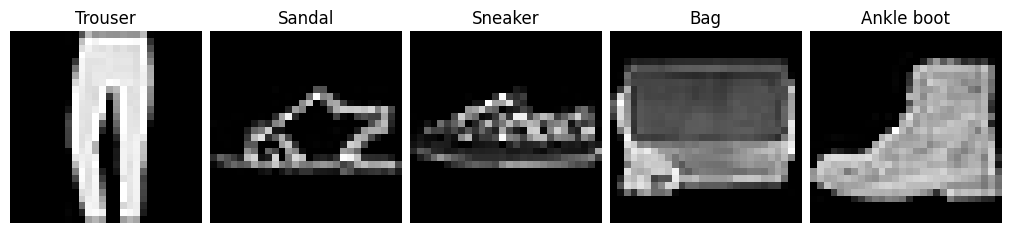

In [ ]:
training_data = FashionMNIST(root=str(DATA_ROOT), train=True, download=DOWNLOAD)
labels = training_data.targets.numpy()
target_indices = np.flatnonzero(np.isin(labels, TARGET_CLASS_IDS))
training_pool, validation_indices = train_test_split(target_indices, test_size=5000, stratify=labels[target_indices], random_state=SEED)
training_indices, _ = train_test_split(training_pool, train_size=5000, stratify=labels[training_pool], random_state=SEED)
label_map = torch.full((10,), -1, dtype=torch.long)
label_map[list(TARGET_CLASS_IDS)] = torch.arange(5)
train_images = training_data.data[training_indices].float().unsqueeze(1) / 255.0
validation_images = training_data.data[validation_indices].float().unsqueeze(1) / 255.0
train_targets = label_map[training_data.targets[training_indices]]
validation_targets = label_map[training_data.targets[validation_indices]]
print('Training / validation images:', len(train_images), '/', len(validation_images))

figure, axes = plt.subplots(1, 5, figsize=(10, 3), layout='constrained')
for category, axis in enumerate(axes):
    position = int(torch.nonzero(train_targets == category)[0].item())
    axis.imshow(train_images[position, 0], cmap='gray', vmin=0, vmax=1)
    axis.set_title(CLASS_NAMES[category])
    axis.axis('off')
plt.show()

## Prepare the input features

### Establish a baseline

Train a linear classifier directly on the **784 pixel values**. Also report the score from always guessing one category: **20%** with five balanced categories.

The ResNet classifier uses the same type of linear head, but receives **512 pretrained features** instead of pixels. Both heads receive the same training labels and validation procedure.

### Reuse the pretrained CNN

ResNet-18 was trained on ImageNet. Replace its original 1,000-class classifier with `Identity`, which passes through the 512 features before the classifier. Freeze all CNN weights.

Call `eval()` as well: it keeps ResNet's batch-normalization statistics fixed. Disabling gradients alone does not do that.

Repeat each grayscale image across three channels, then apply the resizing, cropping and normalization supplied with the pretrained weights. This matches the model's expected input but adds no image detail; cropping can remove image edges.

Calculate features once and cache them in `00_Data/resnet18-features/`. These generated caches can be rebuilt from the reference images and pretrained weights. The cache key includes the images, preprocessing, weight name, device and package versions. Reusing a cache does not train the CNN or mix the data splits.

In [3]:
weights = ResNet18_Weights.IMAGENET1K_V1
preprocess = weights.transforms()
encoder = resnet18(weights=weights)
feature_count = encoder.fc.in_features
encoder.fc = nn.Identity()
encoder.requires_grad_(False)
encoder.to(DEVICE).eval();
print('Features per image:', feature_count)

FEATURE_CACHE = DATA_ROOT / 'resnet18-features'
FEATURE_CACHE.mkdir(parents=True, exist_ok=True)

def extract_features(images):
    recipe = f'{weights}|{preprocess}|{DEVICE}|{torch.__version__}|{torchvision.__version__}'
    key = sha256(recipe.encode() + images.numpy().tobytes()).hexdigest()
    cache_path = FEATURE_CACHE / f'{key}.pt'
    if cache_path.exists():
        print('Using cached features for', len(images), 'images')
        return torch.load(cache_path, map_location='cpu', weights_only=True)
    started = time.monotonic()
    batches = []
    encoder.eval()
    with torch.no_grad():
        for position, batch in enumerate(images.split(BATCH_SIZE)):
            inputs = preprocess(batch.repeat(1, 3, 1, 1)).to(DEVICE)
            batches.append(encoder(inputs).cpu())
            if (position + 1) % 20 == 0:
                print('Images processed:', min((position + 1) * BATCH_SIZE, len(images)), '/', len(images), flush=True)
    features = torch.cat(batches)
    torch.save(features, cache_path)
    print(f'Extracted {len(images):,} images in {time.monotonic() - started:.1f} seconds')
    return features

train_features = extract_features(train_images)
validation_features = extract_features(validation_images)
print('Training feature matrix:', tuple(train_features.shape))

Features per image: 512
Using cached features for 5000 images
Using cached features for 5000 images
Training feature matrix: (5000, 512)


## Train the classification heads

The new ResNet head is `Linear(512, 5)`: it maps the pretrained features to five category scores. `CrossEntropyLoss` compares these scores with the true categories. **Do not add softmax before this loss.**

Use the same training function for the pixel baseline and ResNet head. It saves the weights with the best validation accuracy and stops when that score has not improved for five epochs.

Only the head's weights and biases change. The feature arrays are fixed, and no gradient flows into the CNN. Neither head trains on test images.

Accuracy is suitable for this balanced five-category example. Later, use the confusion matrix to inspect individual category errors rather than relying only on the overall score.

In [4]:
def train_head(training_features, validation_features):
    torch.manual_seed(SEED)
    head = nn.Linear(training_features.shape[1], 5)
    optimizer = torch.optim.Adam(head.parameters(), lr=0.001)
    loader = DataLoader(TensorDataset(training_features, train_targets), batch_size=256, shuffle=True, generator=torch.Generator().manual_seed(SEED))
    best_accuracy, best_epoch = -1.0, 0
    best_weights = deepcopy(head.state_dict())
    for epoch in range(1, HEAD_EPOCHS + 1):
        head.train()
        for inputs, targets in loader:
            optimizer.zero_grad()
            loss = nn.functional.cross_entropy(head(inputs), targets)
            loss.backward()
            optimizer.step()
        head.eval()
        with torch.no_grad():
            predicted = head(validation_features).argmax(dim=1)
            accuracy = (predicted == validation_targets).float().mean().item()
        if accuracy > best_accuracy:
            best_accuracy, best_epoch = accuracy, epoch
            best_weights = deepcopy(head.state_dict())
        if epoch - best_epoch >= 5:
            break
    head.load_state_dict(best_weights)
    print(f'Selected epoch {best_epoch}; validation accuracy {best_accuracy:.1%}')
    return head, best_accuracy

pixel_head, pixel_validation = train_head(train_images.flatten(1), validation_images.flatten(1))
resnet_head, resnet_validation = train_head(train_features, validation_features)
validation_results = pd.Series({'Raw pixels + head': pixel_validation, 'Frozen ResNet-18 + head': resnet_validation}, name='Validation accuracy')
selected_model = validation_results.idxmax()
print('Model chosen using validation images:', selected_model)
display((100 * validation_results).rename('Validation accuracy (%)').round(2).to_frame())
print('Trainable weights in the ResNet head:', sum(parameter.numel() for parameter in resnet_head.parameters()))

Selected epoch 30; validation accuracy 93.5%


Selected epoch 28; validation accuracy 95.9%
Model chosen using validation images: Frozen ResNet-18 + head


,Validation accuracy (%)
Raw pixels + head,93.46
Frozen ResNet-18 + head,95.92


Trainable weights in the ResNet head: 2565


## Evaluate the trained models

Only now load the official test images. The fixed CNN processes each image separately; neither preprocessing nor the heads are fitted on test data.

Report test accuracy for both trained heads and the one-category guessing rule. Keep the model selected using validation data, even if another model happens to score higher on the test set. **Do not use test results to adjust the models.**

This compares complete pipelines, not pretraining alone: the pixel model uses the original image, while ResNet includes resizing, cropping and learned features. Their total training costs are also different because ResNet brings substantial external pretraining.

In [ ]:
test_data = FashionMNIST(root=str(DATA_ROOT), train=False, download=DOWNLOAD)
test_indices = np.flatnonzero(np.isin(test_data.targets.numpy(), TARGET_CLASS_IDS))
test_images = test_data.data[test_indices].float().unsqueeze(1) / 255.0
test_targets = label_map[test_data.targets[test_indices]]
test_features = extract_features(test_images)
with torch.no_grad():
    test_predictions = {
        'Guess one category': np.full(len(test_targets), int(torch.bincount(train_targets).argmax())),
        'Raw pixels + head': pixel_head(test_images.flatten(1)).argmax(dim=1).numpy(),
        'Frozen ResNet-18 + head': resnet_head(test_features).argmax(dim=1).numpy(),
    }
test_results = pd.Series({name: 100 * accuracy_score(test_targets.numpy(), predicted) for name, predicted in test_predictions.items()}, name='Test accuracy (%)')
display(test_results.round(2).to_frame())
print('Validation-selected model:', selected_model)
print('Selected model test accuracy:', f'{test_results[selected_model]:.2f}%')

Using cached features for 5000 images


,Test accuracy (%)
Guess one category,20.00
Raw pixels + head,93.56
Frozen ResNet-18 + head,96.00


Validation-selected model: Frozen ResNet-18 + head
Selected model test accuracy: 96.00%


## Interpret the predictions

The confusion matrix shows errors for the classifier selected using validation images. Rows are true categories; columns are predictions. Which mix-ups would make the shop's catalog harder to use?

The image grid shows the first test example of each category, not examples chosen because the model was correct. These are examples of predictions, **not explanations of which pixels caused them**.

The 512 features have no predefined names such as shoe height or sleeve length. Accurate predictions do not establish causal relationships or explain how customers will respond.

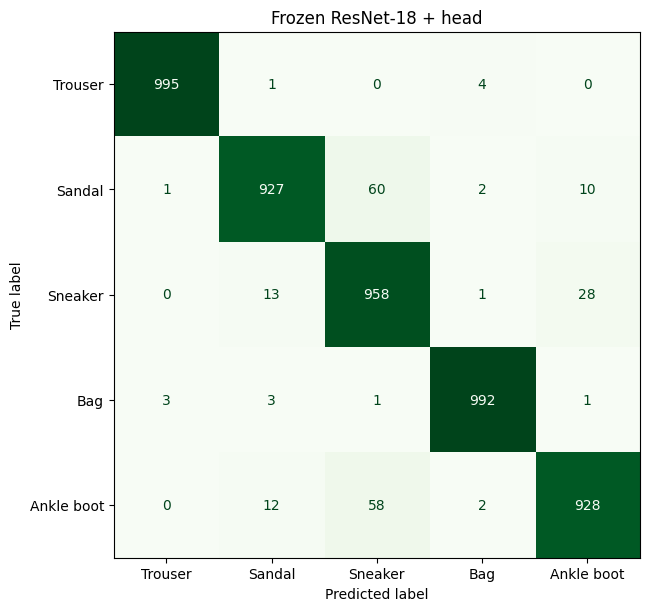

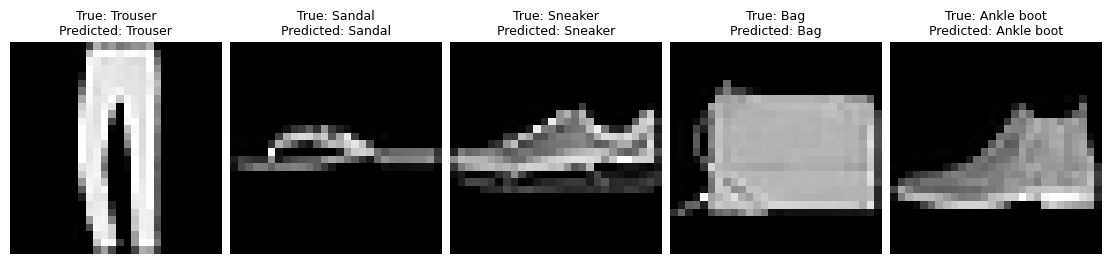

In [6]:
selected_predictions = test_predictions[selected_model]
figure, axis = plt.subplots(figsize=(7, 6), layout='constrained')
ConfusionMatrixDisplay.from_predictions(test_targets.numpy(), selected_predictions, display_labels=CLASS_NAMES, values_format='d', colorbar=False, cmap='Greens', ax=axis)
axis.set_title(selected_model)
plt.show()

figure, axes = plt.subplots(1, 5, figsize=(11, 3), layout='constrained')
for category, axis in enumerate(axes):
    position = int(torch.nonzero(test_targets == category)[0].item())
    axis.imshow(test_images[position, 0], cmap='gray', vmin=0, vmax=1)
    axis.set_title(f'True: {CLASS_NAMES[category]}\nPredicted: {CLASS_NAMES[selected_predictions[position]]}', fontsize=9)
    axis.axis('off')
plt.show()

## Summary and exercises

- Transfer learning reuses the frozen CNN's visual features and trains a small classification head.
- Compare that pipeline with the raw-pixel baseline using the same training labels and validation procedure. Reuse is useful only if the evidence supports it.
- A useful shop system needs more than benchmark accuracy: measure category errors, correction costs, catalog search quality and inference cost on representative product photos.

### Limits to remember

- Fashion-MNIST images are small, grayscale and centered. ImageNet images and real catalog photos are different; resizing cannot restore missing detail.
- This is one seed and one training-label budget. Small score differences may not hold in another run.
- The 5,000-label budget applies only to target training. Validation uses more labels, and ImageNet pretraining used additional labels and computation.
- The pipelines use different preprocessing and representations. This comparison does not isolate the effect of pretraining alone.
- Review pretraining data rights and possible overlap with a target application before deployment. Do not use this test set for further tuning.

## Check your understanding

1. Which weights change when we train the ResNet pipeline? Why also call `eval()`?
2. How much better or worse is the ResNet pipeline than the pixel baseline? Does that establish value for a real shop?
3. Why can we cache features here, but not reuse that cache while fine-tuning the CNN?

<details>
<summary>Answers and self-check criteria</summary>

1. **Basic, 3 points:** only the head's weights and biases change (1); the CNN remains frozen (1); `eval()` keeps batch-normalization statistics fixed (1). Common mistake: assuming that disabling gradients also enables evaluation mode.
2. **Intermediate, 3 points:** subtract the two accuracies to obtain a percentage-point gap (1); inspect category errors (1); explain that real-photo performance and business costs need separate evidence (1). Common mistake: confusing percentage points with relative percent improvement or assuming transfer learning must win.
3. **Intermediate, 3 points:** a frozen encoder and fixed preprocessing give a fixed mapping (1); changing CNN weights changes its features (1); cached features cannot supply gradients through the CNN (1). Common mistake: training on an old feature cache and calling it CNN fine-tuning.

</details>

### Optional exercise

Fine-tune part of the CNN with a smaller learning rate, using training and validation images only. This needs a separate training loop; cached features are no longer sufficient when encoder weights change. Plan fresh evaluation data before using earlier test results to guide changes.

<details>
<summary>Dataset details and further reading</summary>

**Required student source:** Zalando Research. *Fashion-MNIST*: dataset and class labels. https://github.com/zalandoresearch/fashion-mnist .

**Official technical documentation:**
- torchvision 0.17, *resnet18*: weights and their preprocessing. https://docs.pytorch.org/vision/0.17/models/generated/torchvision.models.resnet18.html
- PyTorch, *Transfer Learning for Computer Vision Tutorial*: https://pytorch.org/tutorials/beginner/transfer_learning_tutorial.html

**Optional instructor reference:** He, K., Zhang, X., Ren, S., & Sun, J. (2016). *Deep Residual Learning for Image Recognition*. CVPR. https://arxiv.org/abs/1512.03385 .

Results come from this notebook's executed cells, not published ImageNet benchmark scores. Use validation-selected choices and keep the historical test results fixed.

</details>

### Jupyter notebook --footer info--

Operating system, date/time and Python version for this notebook session.

In [ ]:
import os
import platform
from datetime import datetime
from platform import python_version

print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime('%Y-%m-%d %H:%M:%S'))
print('Python Version:', python_version())
print('-----------------------------------')